# Dynamische reactorrespons van het BEP

**Verkennende simulatie · eindige radiale diffusie · geen externe filmweerstand**

Deze notebook bouwt voort op de bestaande `pbr`-modules. Pas de configuratiecel aan om rooster, frequentie, modulatie en rekentoleranties te wijzigen. De notebook toont de invoer en uitlaat, axiale en radiale concentratieprofielen, een controle op periodieke ingeregeldheid en een gevoeligheidsvergelijking van pelletstraal `R`, effectieve diffusiviteit `D_e` en `R²/D_e`.

> **Reikwijdte.** De uitvoer is een reproduceerbare verkenning met het gecatalogiseerde literatuurmodel. Dit is geen kalibratie of experimentele validatie van Damian’s BEP. De herkomst en aannames staan hieronder bij het model.

## Fysica in deze berekening

- De gasconcentratie wordt langs het bed getransporteerd met plug flow. Axiale dispersie staat uit.
- De pellet is bolvormig en heeft eindige, celgecentreerde radiale volumes. In het centrum geldt symmetrie; op het oppervlak geldt `c_p(R,t) = C_b(z,t)`. Dit is de Dirichlet-grensvoorwaarde zonder externe filmweerstand.
- Met de porositeit-inclusieve diffusiviteit `D_e = ε_p D_m/τ` gebruikt de code in de poriën `D_e/ε_p`. De bulk en pellet wisselen dezelfde radiale oppervlaktestroom met tegengesteld teken uit. De reactie wordt één keer, in de pelletbalans, geteld.
- De Urmes-ratewet sluit de oppervlaktebedekking algebraïsch (quasi-stationair). De notebook modelleert dus geen vertraagde adsorptie/desorptie of dynamische katalysatorbedekking.

De natuurlijke diffusietijd van de gebruikte poriënvergelijking is **`τ_D = ε_p R²/D_e`**. De notebook toont ook de gevraagde kale verhouding `R²/D_e`; beide zijn zichtbaar, omdat `D_e` hier porositeit-inclusief is.

De laatste-periodetoets vergelijkt opeenvolgende uitlaatcurves op dezelfde fase. Een periodepaar slaagt wanneer voor iedere component de relatieve RMS-afwijking ten hoogste de ingestelde tolerantie is. Dit is een numerieke analyseheuristiek, geen experimenteel criterium.

In [1]:
from dataclasses import replace
from importlib.metadata import version
from pathlib import Path
from time import perf_counter
import os
import platform
import sys

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "pbr").is_dir():
    REPO_ROOT = (REPO_ROOT / "..").resolve()
if not (REPO_ROOT / "pbr").is_dir():
    raise RuntimeError("Start this notebook from the Methanol-Catalysis repository")
os.chdir(REPO_ROOT)
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display

from pbr import Inputs, build_model, effective_diffusivities, make_inlet
from pbr.parameters import AdvectionScheme, OperatingPoint
from pbr.parameter_sets import PROVENANCE
from pbr.species import GASES, Gas
from notebooks.bep_response_analysis import (
    analyse_settled_cycles,
    plot_axial_profiles,
    plot_cycle_overlay,
    plot_inlet_outlet,
    plot_parameter_comparison,
    plot_radial_heatmaps,
    plot_radial_profiles,
    plot_settling_diagnostics,
    sample_solution_by_period,
    set_plot_style,
)

set_plot_style()
SPECIES_NAMES = tuple(gas.value for gas in GASES)
FIGURE_DIR = Path("notebooks/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## Eenvoudige configuratie

De startset urmes2019 levert de gedocumenteerde kinetiek en standaardcondities. De waarden hieronder zijn rechtstreeks te wijzigen. Laat temperatuur, druk of debiet op None om de cataloguswaarde te gebruiken. De standaard diffusiviteit komt uit de bestaande Fuller-helper; een handmatige diffusiviteit is alleen bedoeld voor een traceerbare eigen bron of meting.

Deze standaardconfiguratie blijft een code-diagnose met overgedragen geometrie- en porositeitsaannames. Een parameterwijziging maakt de run niet automatisch bron-gematcht of experimenteel gevalideerd.

In [2]:
# Bewerk deze waarden voor een eerste verkenning.
KINETIC_SET = "urmes2019"
RADIUS_UM = 75.0
PARTICLE_POROSITY = 0.50
TEMPERATURE_K = None       # None houdt de temperatuur uit KINETIC_SET aan
PRESSURE_PA = None         # None houdt de druk uit KINETIC_SET aan
VOLUMETRIC_FLOW_M3_S = None  # None houdt het debiet uit KINETIC_SET aan
DIFFUSIVITY_OVERRIDE_M2_S = None  # None berekent soortspecifieke D_e met Fuller

N_AXIAL = 8
N_RADIAL = 12               # aantal radiale controlevolumes
FORCING_HZ = 200.0
RELATIVE_MODULATION = 0.10  # cosinusmodulatie van alle gevolgde componenten
N_PERIODS = 16
SAMPLES_PER_PERIOD = 60
SETTLE_TOLERANCE = 0.01
SETTLE_REQUIRED_PAIRS = 5
METHOD = "BDF"
RTOL = 1e-4
ATOL = 1e-8

assert RADIUS_UM > 0
assert 0 < PARTICLE_POROSITY < 1
assert N_PERIODS >= SETTLE_REQUIRED_PAIRS + 1
PERIOD = 1.0 / FORCING_HZ

## Herkomst en aannames

De kinetische constanten, temperatuur, druk, voeding en debiet komen uit de bestaande Urmes 2019-set in pbr. De catalogus combineert die met een reactorconfiguratie die niet volledig met het gepubliceerde bronexperiment overeenkomt. De straal van 75 µm is het midden van de gedocumenteerde zeefklasse; de pelletporositeit, deeltjesdichtheid en tortuositeit zijn overgedragen aannames, geen BEP-pelletmetingen.

De Fuller-correlatie levert de soortspecifieke gasdiffusiviteit; pbr past de Pa-naar-atm en cm²/s-naar-m²/s conversies toe. D_e = ε_p D_m/τ is een afgeleide schatting, geen gemeten effectieve diffusiviteit voor deze pellet. De handmatige override hierboven accepteert alleen een volledige mapping voor de vier reactieve gassen.

De gekozen randvoorwaarde is expliciet c_p(R,t) = C_b(z,t), zonder externe filmweerstand. De radiale pellet blijft eindig en celgecentreerd. De ratewet gebruikt algebraïsche, quasi-stationaire oppervlaktebedekkingen. De notebook schakelt geen vertragingsmodel voor bedekkingen in: de Relaxation-optie is geen vervanging voor bron-onderbouwde dynamische kinetiek.

De oorspronkelijke diagnostiek op [PM issue #58](https://github.com/AsapLoso/project-management-agents/issues/58#issuecomment-6257428574) onderzocht de oudere main-commit 5400881. De [kruiscontrole op PR #1](https://github.com/AsapLoso/Methanol-Catalysis/pull/1#issuecomment-6260001345) noemt de correcties op PR-head 791e51c expliciet als nog onafhankelijk te verifiëren. Deze V2-branch voert die checks opnieuw uit; de eerdere diagnose geldt niet als bewijs tegen of voor de PR #1-code.

Urmès 2019 rapporteert steady-state controles voor externe en interne massatransportbeperking onder de auteurscondities. Dat maakt een transient zonder interne pelletdiffusie niet gerechtvaardigd en valideert de hier gebruikte BEP-transient evenmin.

In [3]:
assumption_names = (
    "catalyst.particle_radius",
    "catalyst.particle_porosity",
    "catalyst.particle_density",
    "catalyst.tortuosity",
    "geometry.tube_inner_diameter",
    "geometry.catalyst_mass",
    "geometry.bed_void_fraction",
    "transport.effective_diffusivity",
    "transport.external_film",
    "transport.axial_dispersion",
)
rows = [
    (name, PROVENANCE[name].source.value, PROVENANCE[name].reference,
     PROVENANCE[name].locator, PROVENANCE[name].note)
    for name in assumption_names
]
header = "| Grootheid | Status | Bron | Locatie | Toelichting |\n|---|---|---|---|---|"
body = "\n".join(
    f"| `{name}` | {kind} | `{source}` | {locator} | {note} |"
    for name, kind, source, locator, note in rows
)
display(Markdown(header + "\n" + body))

| Grootheid | Status | Bron | Locatie | Toelichting |
|---|---|---|---|---|
| `catalyst.particle_radius` | derived | `urmesKineticStudySelective2019` | Table 1, sieve fraction 100-200 um | radius = 150 um / 2 = 75 um, the midpoint of the fraction |
| `catalyst.particle_porosity` | assumed | `bergerDynamicMethodsCatalytic2008` | Case 6.4 pellet porosity | transferred from an Na/gamma-Al2O3 sorbent, not from this catalyst |
| `catalyst.particle_density` | assumed | `bergerDynamicMethodsCatalytic2008` | Case 6.4 particle density | 1550 kg/m3, an alumina pellet from a different study |
| `catalyst.tortuosity` | assumed | `dehghaniExperimentalApproachIndustrial2019` | reactor description | tau = 2.5 reported there; 3.0 used here as an alumina-typical value |
| `geometry.tube_inner_diameter` | literature | `larsenSemihydrogenationAcetyleneEthylene2024` | Appendix F | 5.0 mm |
| `geometry.catalyst_mass` | assumed | `larsenSemihydrogenationAcetyleneEthylene2024` | Appendix F, W_cat | 75 mg is the source's Pd2Ag bed; kept for the reactor match |
| `geometry.bed_void_fraction` | assumed | `bergerDynamicMethodsCatalytic2008` | Case 6.4 | 0.45 is the assumed working value; 0.50 is reported for a packed alumina bed in a different study and is contextual only |
| `transport.effective_diffusivity` | derived | `fullerSchettlerGiddings1966` | Eq. for gas-phase diffusivity | D_e = eps_p D_m / tau with D_m from the Fuller correlation; pressure is converted from Pa to atm and D from cm^2/s to m^2/s |
| `transport.external_film` | derived | `urmesKineticStudySelective2019` | Table 7, Carberry 3.3e-4 | Ca << 0.05 at this catalyst, so the film closure is inactive by default |
| `transport.axial_dispersion` | derived | `danckwertsContinuousFlowSystems1953` | Eq. 30 | D_Lu = 0.018 of u_s*d_p; the closure defaults to zero (plug flow) |

## Model opbouwen en periodieke invoer opleggen

De beginstaat is een uniform bed en pellet met de invoerconcentratie op fase nul (de cosinuspiek). De eerste perioden bevatten daarom ook de overgang naar periodiek bedrijf; de laatste-periodetoets controleert of die invloed is verdwenen.

In [4]:
base_inputs = Inputs.catalogued(KINETIC_SET)
if RADIUS_UM <= 0:
    raise ValueError("RADIUS_UM must be positive")
if not 0 < PARTICLE_POROSITY < 1:
    raise ValueError("PARTICLE_POROSITY must lie between 0 and 1")

catalyst = base_inputs.catalyst.model_copy(
    update={
        "particle_radius": RADIUS_UM * 1e-6,
        "particle_porosity": PARTICLE_POROSITY,
    }
)
operating_updates = {
    name: value
    for name, value in {
        "temperature": TEMPERATURE_K,
        "pressure": PRESSURE_PA,
        "volumetric_flow": VOLUMETRIC_FLOW_M3_S,
    }.items()
    if value is not None
}
operating = OperatingPoint.model_validate(
    {**base_inputs.operating.model_dump(), **operating_updates}
)
base_inputs = replace(base_inputs, catalyst=catalyst, operating=operating)
solver = base_inputs.solver.model_copy(
    update={
        "n_axial": N_AXIAL,
        "n_radial": N_RADIAL,
        "radial_geometry": 2,
        "advection_scheme": AdvectionScheme.TVD2,
        "integrator": METHOD,
        "rtol": RTOL,
        "atol": ATOL,
        "max_step": PERIOD / 10.0,
        "use_sparsity": True,
    }
)
base_inputs = replace(base_inputs, solver=solver)
BASE_DIFFUSIVITIES = {
    str(gas): float(value)
    for gas, value in effective_diffusivities(
        base_inputs.catalyst, base_inputs.operating
    ).items()
}
if DIFFUSIVITY_OVERRIDE_M2_S is not None:
    if set(DIFFUSIVITY_OVERRIDE_M2_S) != set(SPECIES_NAMES):
        raise ValueError("D_e override must contain exactly the four gas species")
    BASE_DIFFUSIVITIES = {
        species: float(DIFFUSIVITY_OVERRIDE_M2_S[species])
        for species in SPECIES_NAMES
    }
if any(value <= 0 for value in BASE_DIFFUSIVITIES.values()):
    raise ValueError("Every effective diffusivity must be positive")


def run_case(radius_factor=1.0, diffusivity_factor=1.0):
    # Build and integrate one radius/diffusivity sensitivity case.
    catalyst = base_inputs.catalyst.model_copy(
        update={
            "particle_radius": base_inputs.catalyst.particle_radius * radius_factor
        }
    )
    case_inputs = replace(base_inputs, catalyst=catalyst)
    inlet = make_inlet(
        case_inputs.operating,
        forcing=[(FORCING_HZ, RELATIVE_MODULATION)],
    )
    diffusivities = {
        gas: value * diffusivity_factor
        for gas, value in BASE_DIFFUSIVITIES.items()
    }
    model = build_model(case_inputs, inlet, diffusivities=diffusivities)

    c0 = np.broadcast_to(inlet(0.0), (N_AXIAL, len(GASES))).copy()
    cp0 = np.broadcast_to(
        c0[:, None, :], (N_AXIAL, N_RADIAL, len(GASES))
    ).copy()
    y0 = model.layout.pack(c0, cp0, None)

    started = perf_counter()
    solution = model.integrate(
        y0,
        (0.0, N_PERIODS * PERIOD),
        method=METHOD,
        rtol=RTOL,
        atol=ATOL,
        max_step=PERIOD / 10.0,
        use_sparsity=True,
        dense_output=True,
    )
    elapsed = perf_counter() - started
    if not solution.success:
        raise RuntimeError(solution.message)
    trajectory, phase = sample_solution_by_period(
        model,
        solution,
        start_time=0.0,
        period=PERIOD,
        n_periods=N_PERIODS,
        samples_per_period=SAMPLES_PER_PERIOD,
    )
    return {
        "model": model,
        "solution": solution,
        "trajectory": trajectory,
        "phase": phase,
        "elapsed_s": elapsed,
        "radius_factor": radius_factor,
        "diffusivity_factor": diffusivity_factor,
    }


baseline = run_case()
print(f"Status: {baseline['solution'].message}")
print(f"Integratietijd: {baseline['elapsed_s']:.2f} s · nfev={baseline['solution'].nfev}")
print(
    "Resolutie: "
    f"N_z={N_AXIAL}, N_r={N_RADIAL} · "
    f"R={baseline['model'].grid.r_p * 1e6:.1f} µm · "
    f"ε_p={baseline['model'].derived.particle_porosity:.3f}"
)
print(
    "Concentratiebereik over solverstappen: "
    f"{baseline['solution'].y.min():.4g}–{baseline['solution'].y.max():.4g} mol m⁻³"
)

Status: The solver successfully reached the end of the integration interval.
Integratietijd: 0.46 s · nfev=890
Resolutie: N_z=8, N_r=12 · R=75.0 µm · ε_p=0.500
Concentratiebereik over solverstappen: 0–36.02 mol m⁻³


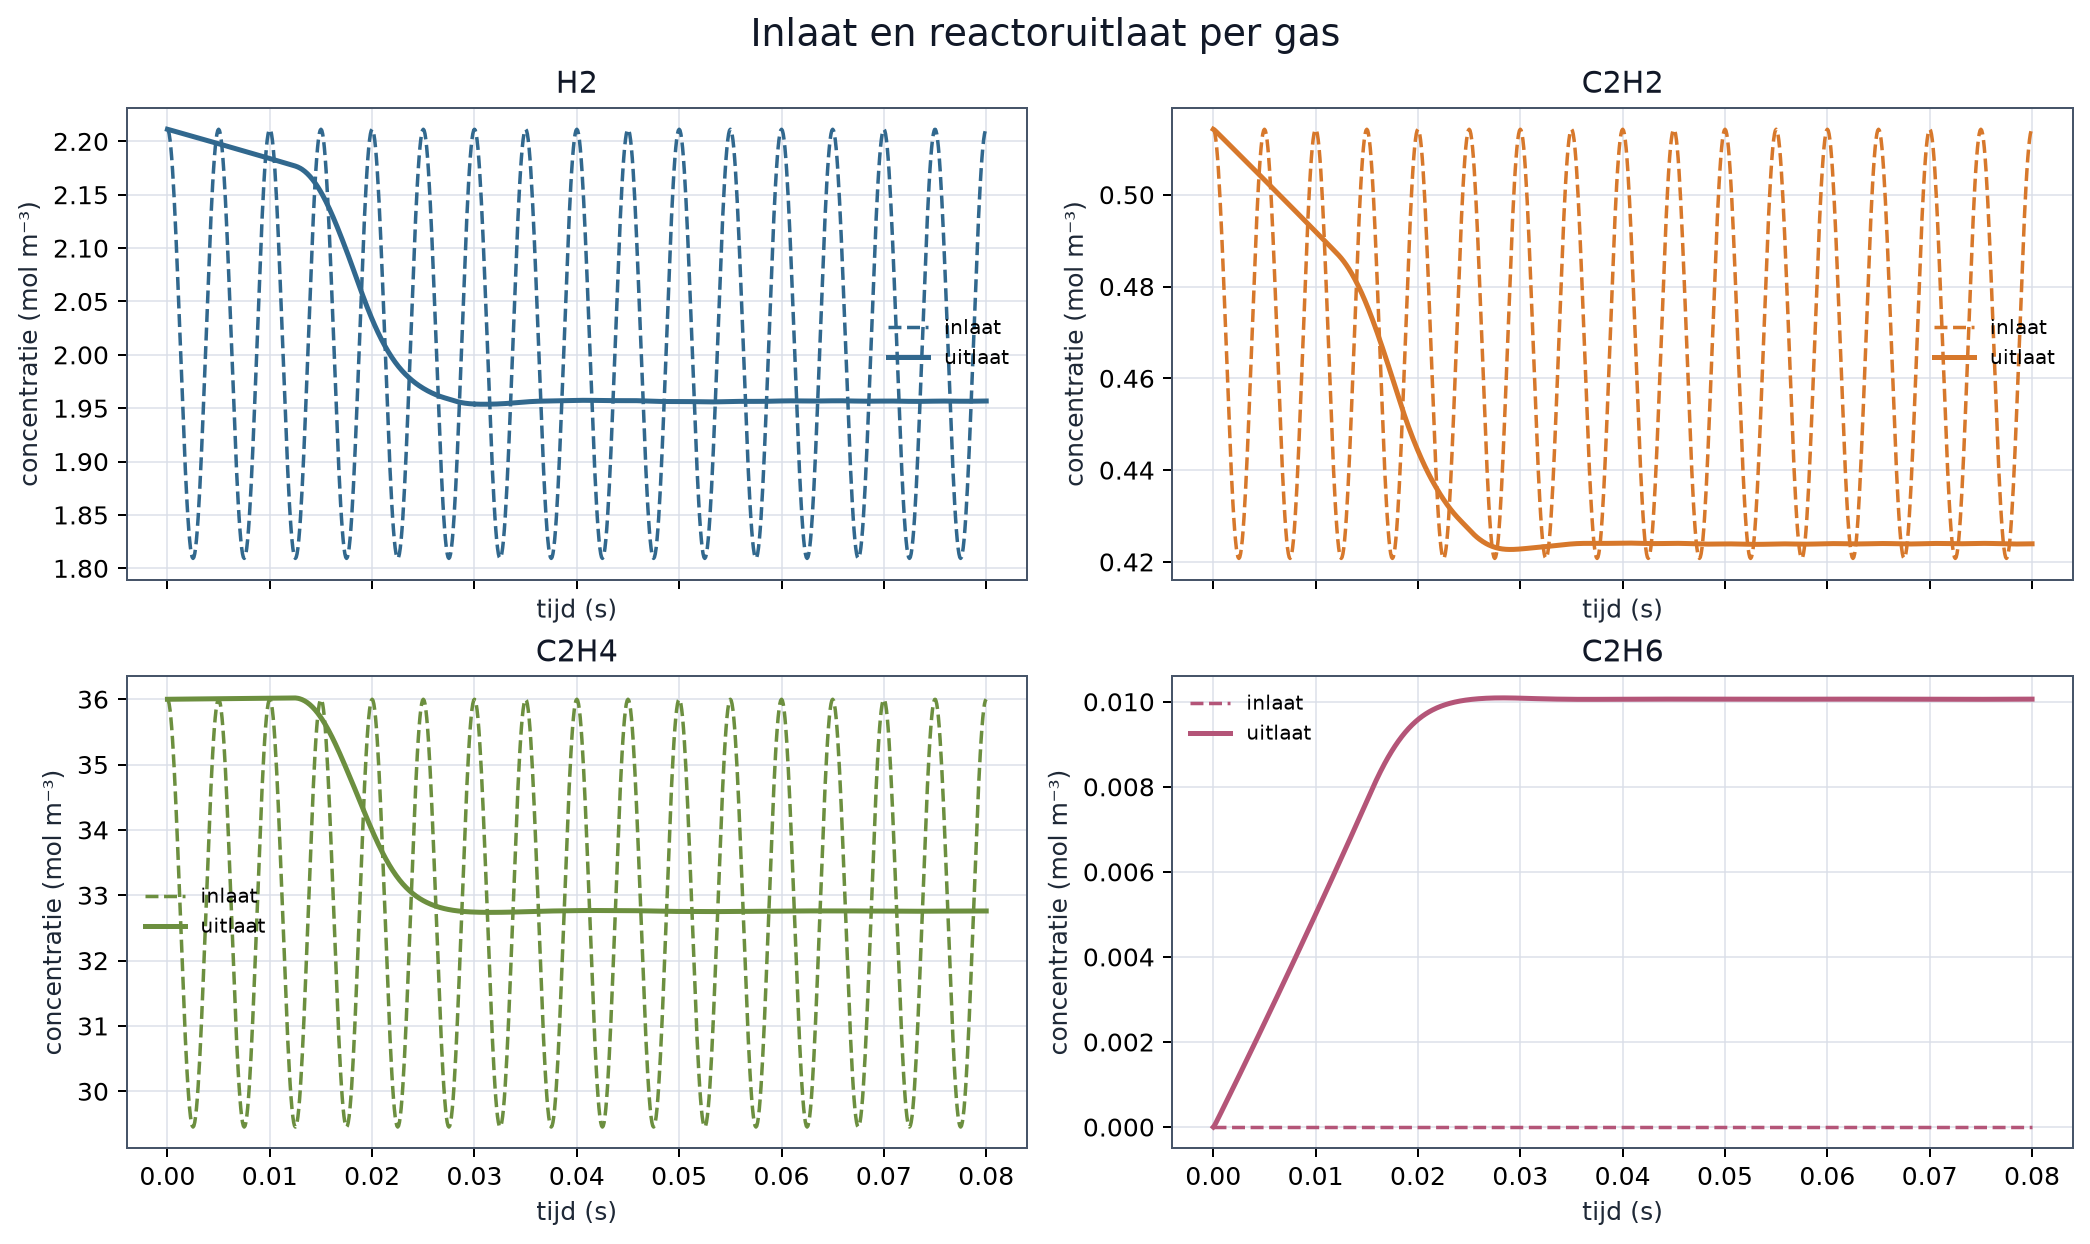

Figuur opgeslagen: notebooks/figures/inlet_outlet.png


In [5]:
def export_figure(figure, filename):
    path = FIGURE_DIR / filename
    figure.savefig(path, dpi=180, bbox_inches="tight")
    display(Image(filename=str(path)))
    plt.close(figure)
    print(f"Figuur opgeslagen: {path}")


full_time = baseline["trajectory"].time.reshape(-1)
full_inlet = baseline["trajectory"].inlet.reshape(-1, len(GASES))
full_bulk = baseline["trajectory"].bulk.reshape(-1, N_AXIAL, len(GASES))
figure, _ = plot_inlet_outlet(full_time, full_inlet, full_bulk, SPECIES_NAMES)
export_figure(figure, "inlet_outlet.png")

## Axiale profielen

De curves zijn uit de laatste berekende periode gekozen. De posities zijn de centra van de axiale cellen.

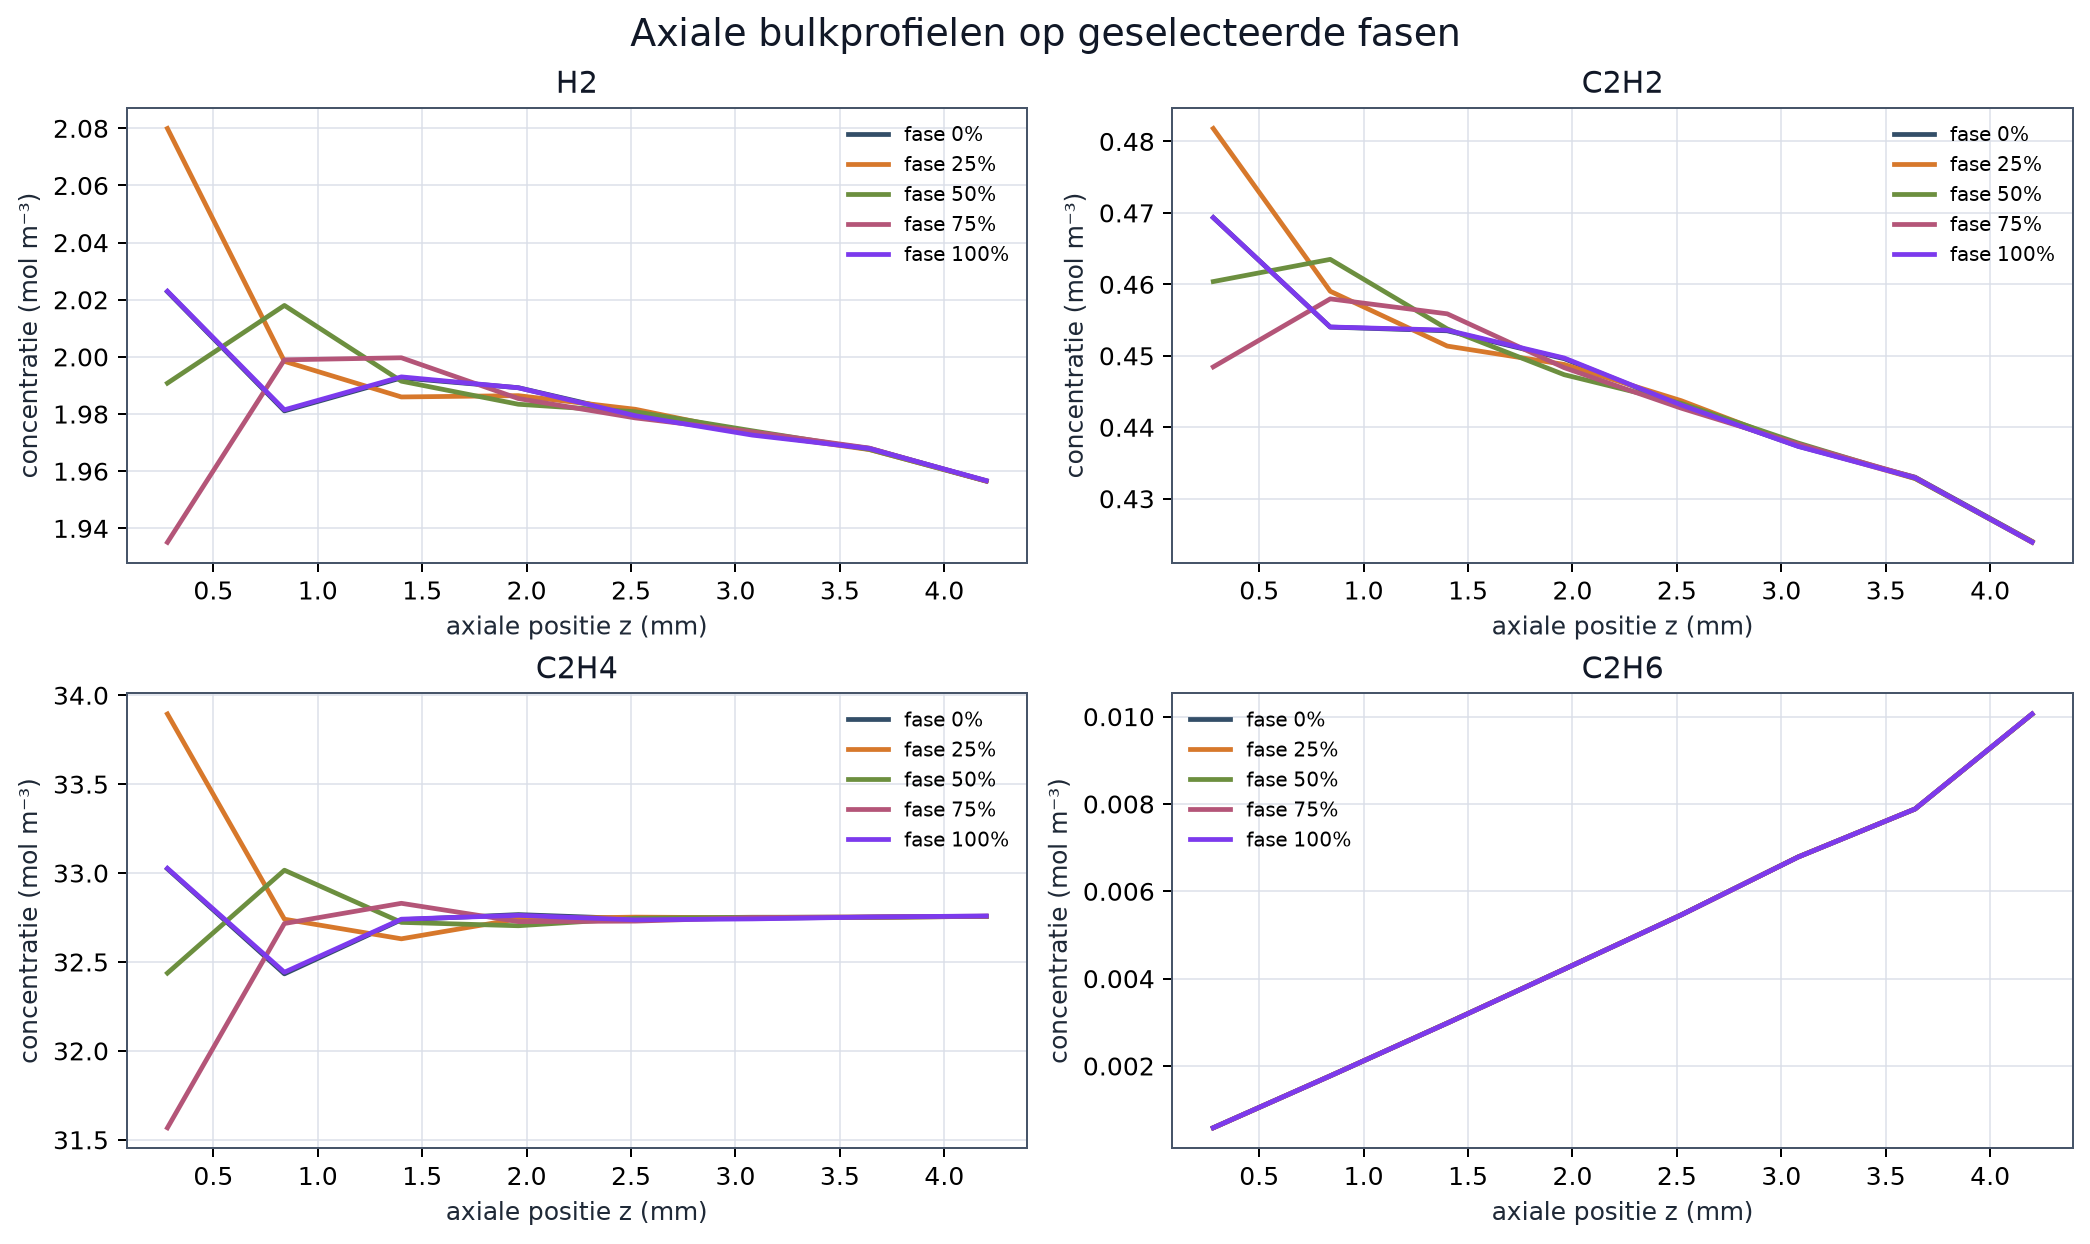

Figuur opgeslagen: notebooks/figures/axial_profiles.png


In [6]:
phase = baseline["phase"]
phase_indices = np.unique(np.linspace(0, SAMPLES_PER_PERIOD, 5, dtype=int))
phase_labels = tuple(
    f"fase {100 * index / SAMPLES_PER_PERIOD:.0f}%" for index in phase_indices
)
z_centers = (np.arange(N_AXIAL) + 0.5) * baseline["model"].derived.dz
bulk_snapshots = baseline["trajectory"].bulk[-1, phase_indices]
figure, _ = plot_axial_profiles(z_centers, bulk_snapshots, SPECIES_NAMES, phase_labels)
export_figure(figure, "axial_profiles.png")

## Radiale pelletprofielen

De lijnplot toont de celgemiddelden op dezelfde fasen als de axiale figuur, bij de laatste axiale cel. De heatmap toont de volledige laatste periode. De celcentra liggen binnen `r/R < 1`; op `r/R = 1` wordt de oppervlaktestaat algebraïsch gelijk aan het bulk gas gezet.

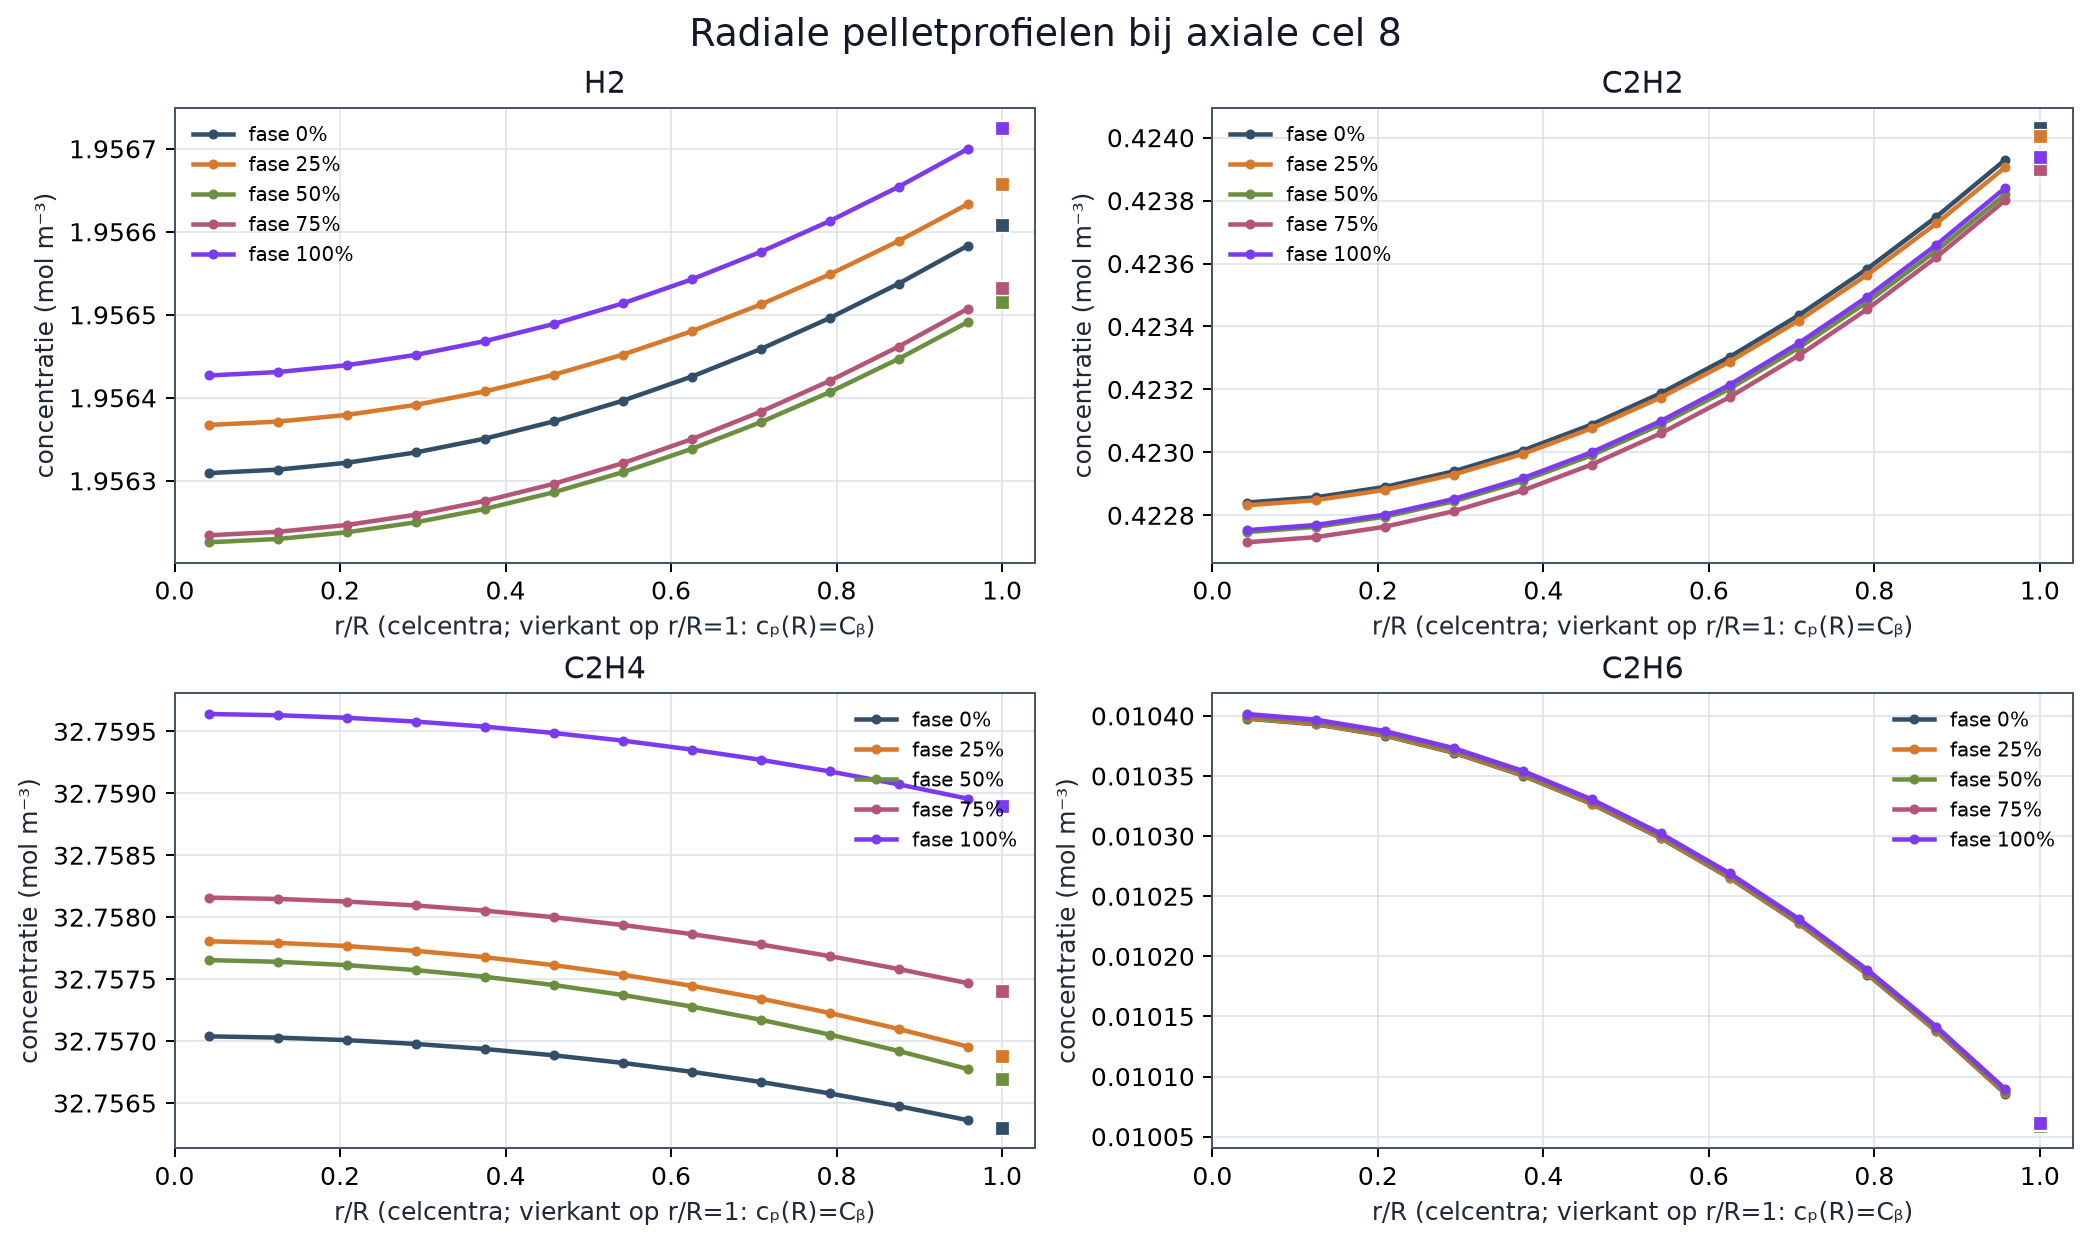

Figuur opgeslagen: notebooks/figures/radial_profiles.png


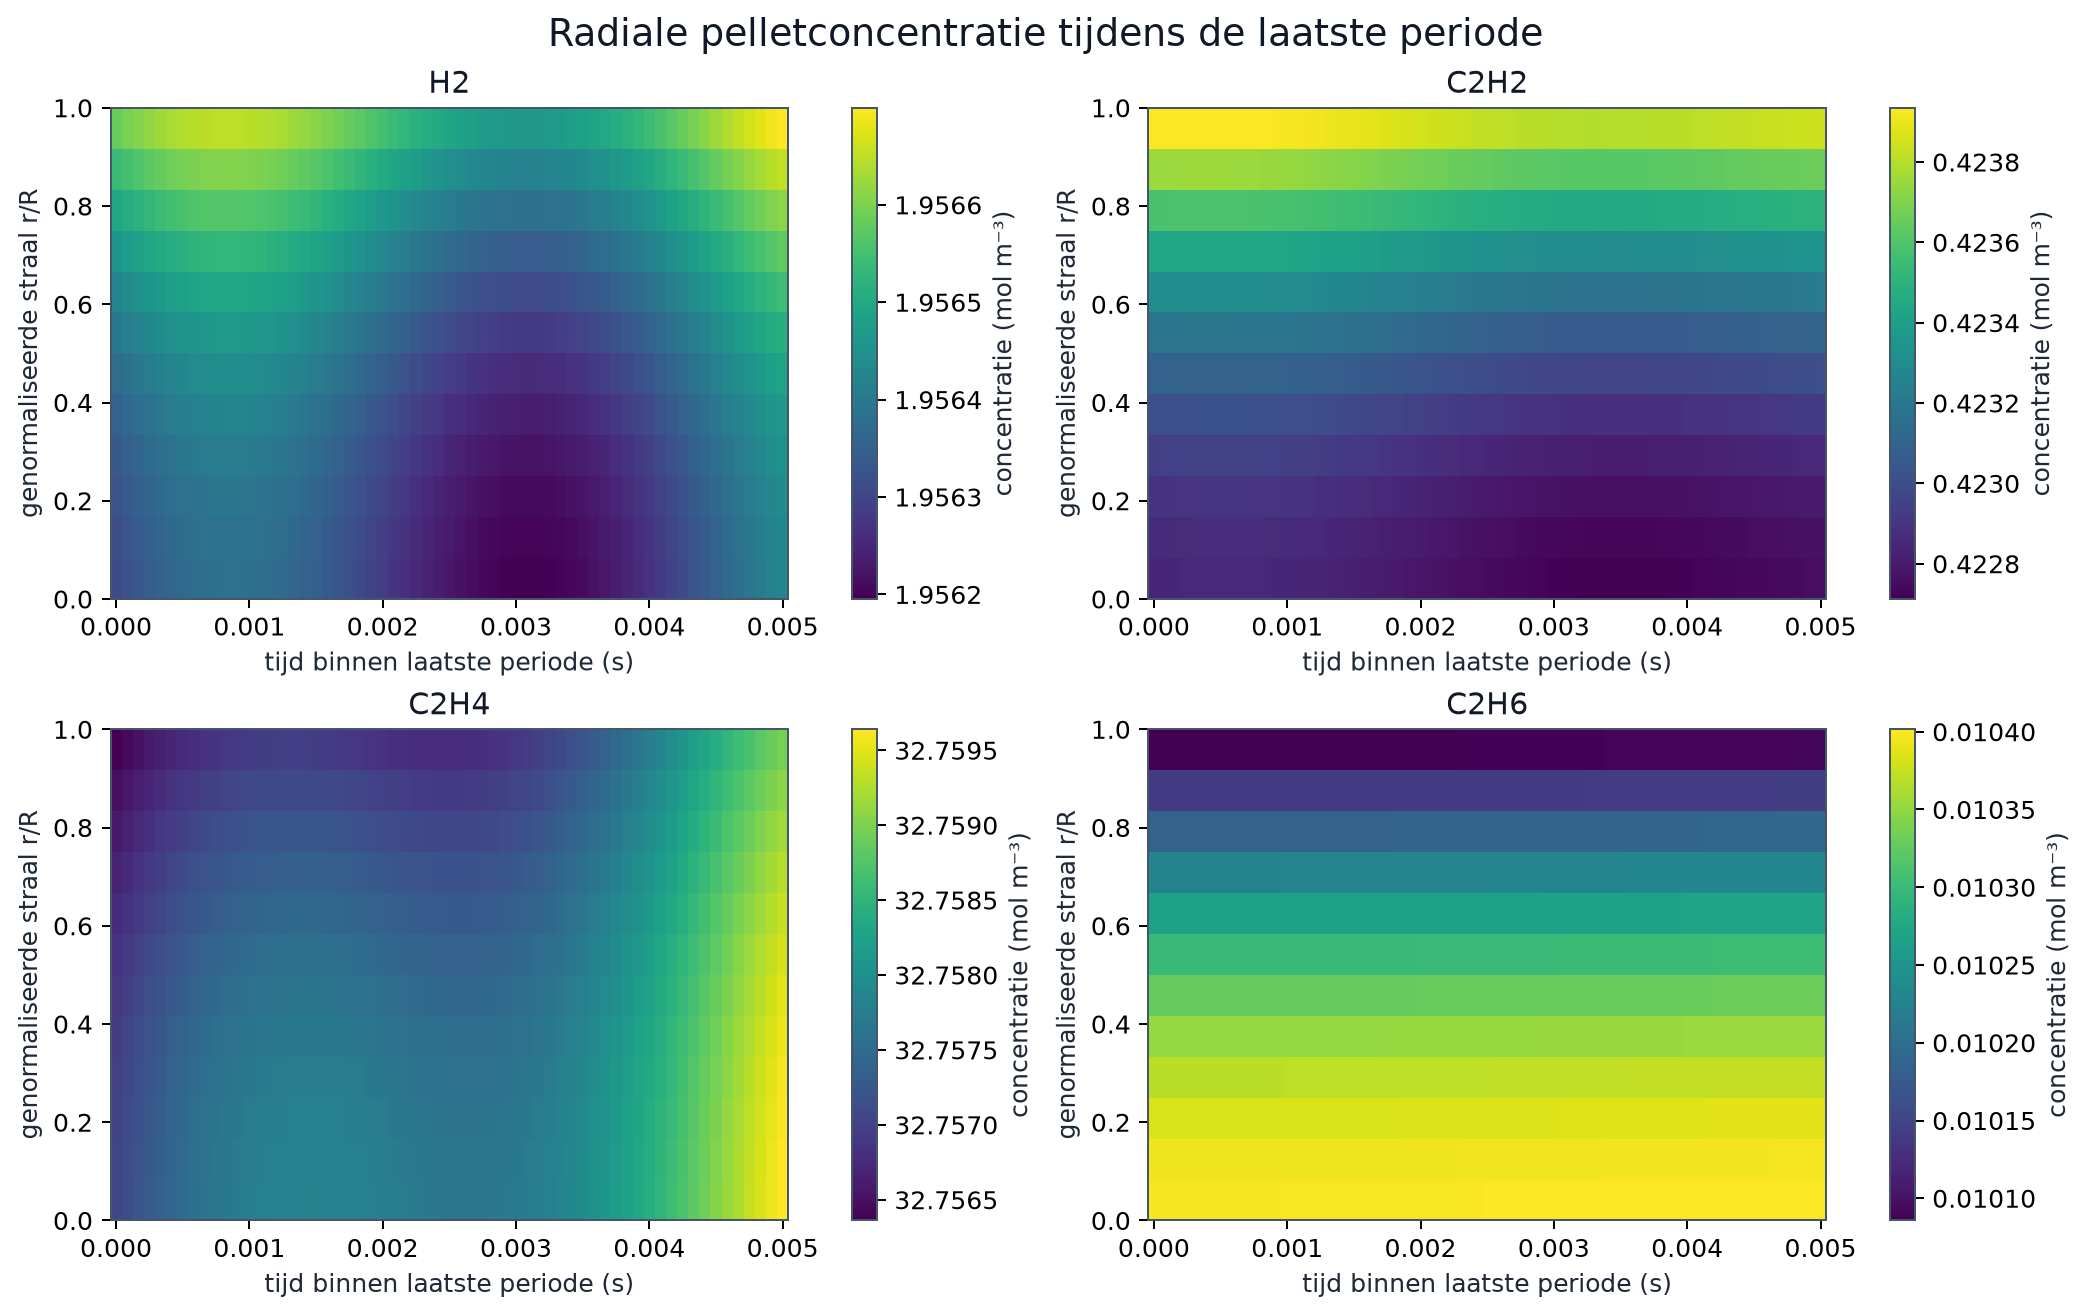

Figuur opgeslagen: notebooks/figures/radial_heatmaps.png


In [7]:
radius_fraction = baseline["model"].grid.r / baseline["model"].grid.r_p
particle_snapshots = baseline["trajectory"].particle[-1, phase_indices]
surface_snapshots = baseline["trajectory"].bulk[-1, phase_indices, -1, :]
figure, _ = plot_radial_profiles(
    radius_fraction,
    particle_snapshots,
    N_AXIAL - 1,
    SPECIES_NAMES,
    phase_labels,
    surface_snapshots=surface_snapshots,
)
export_figure(figure, "radial_profiles.png")

figure, _ = plot_radial_heatmaps(
    phase,
    radius_fraction,
    baseline["trajectory"].particle[-1],
    N_AXIAL - 1,
    SPECIES_NAMES,
)
export_figure(figure, "radial_heatmaps.png")

## Zijn de laatste perioden ingeregeld?

Hieronder worden opeenvolgende uitlaatperioden fase-op-fase vergeleken. De beslissing gebruikt `SETTLE_TOLERANCE` voor **alle** gevolgde gassen en vereist `SETTLE_REQUIRED_PAIRS` opeenvolgende slagende vergelijkingen. Bij onvoldoende perioden luidt de uitkomst expliciet dat ingeregeldheid niet is aangetoond.

Uitkomst: ingeregeld volgens de ingestelde heuristiek
Opeenvolgende slagende periodeparen aan het einde: 10
Start van de aaneengesloten ingeregelde suffix: periode 6
Tolerantie per gas: 1.00% relatieve RMS


| Periodepaar | H₂ | C₂H₂ | C₂H₄ | C₂H₆ | Alle gassen binnen grens? |
|---|---:|---:|---:|---:|---|
| 11 → 12 | 0.02134% | 0.00936% | 0.01616% | 0.01862% | ja |
| 12 → 13 | 0.019% | 0.01192% | 0.01614% | 0.01267% | ja |
| 13 → 14 | 0.00703% | 0.002499% | 0.006233% | 0.01033% | ja |
| 14 → 15 | 0.01012% | 0.008709% | 0.0104% | 0.02304% | ja |
| 15 → 16 | 0.004831% | 0.01263% | 0.005436% | 0.02141% | ja |

De 1%-RMS-grens is een numerieke analyseheuristiek, geen bewijs van fysische of experimentele validiteit.

| Volledige periode | Gas | Gemiddelde C_uit (mol m⁻³) | Halve piek-piek C_uit (mol m⁻³) |
|---:|---|---:|---:|
| 14 | H2 | 1.95671 | 0.00019874 |
| 14 | C2H2 | 0.423956 | 4.87498e-05 |
| 14 | C2H4 | 32.7593 | 0.00179818 |
| 14 | C2H6 | 0.0100601 | 8.87652e-07 |
| 15 | H2 | 1.95652 | 0.000164568 |
| 15 | C2H2 | 0.423991 | 3.71632e-05 |
| 15 | C2H4 | 32.756 | 0.00152366 |
| 15 | C2H6 | 0.0100577 | 8.28876e-07 |
| 16 | H2 | 1.95659 | 0.000118116 |
| 16 | C2H2 | 0.423952 | 6.94674e-05 |
| 16 | C2H4 | 32.7571 | 0.00129697 |
| 16 | C2H6 | 0.010059 | 1.89278e-06 |

Gemiddelden zijn trapeziumintegralen over iedere volledige periode.

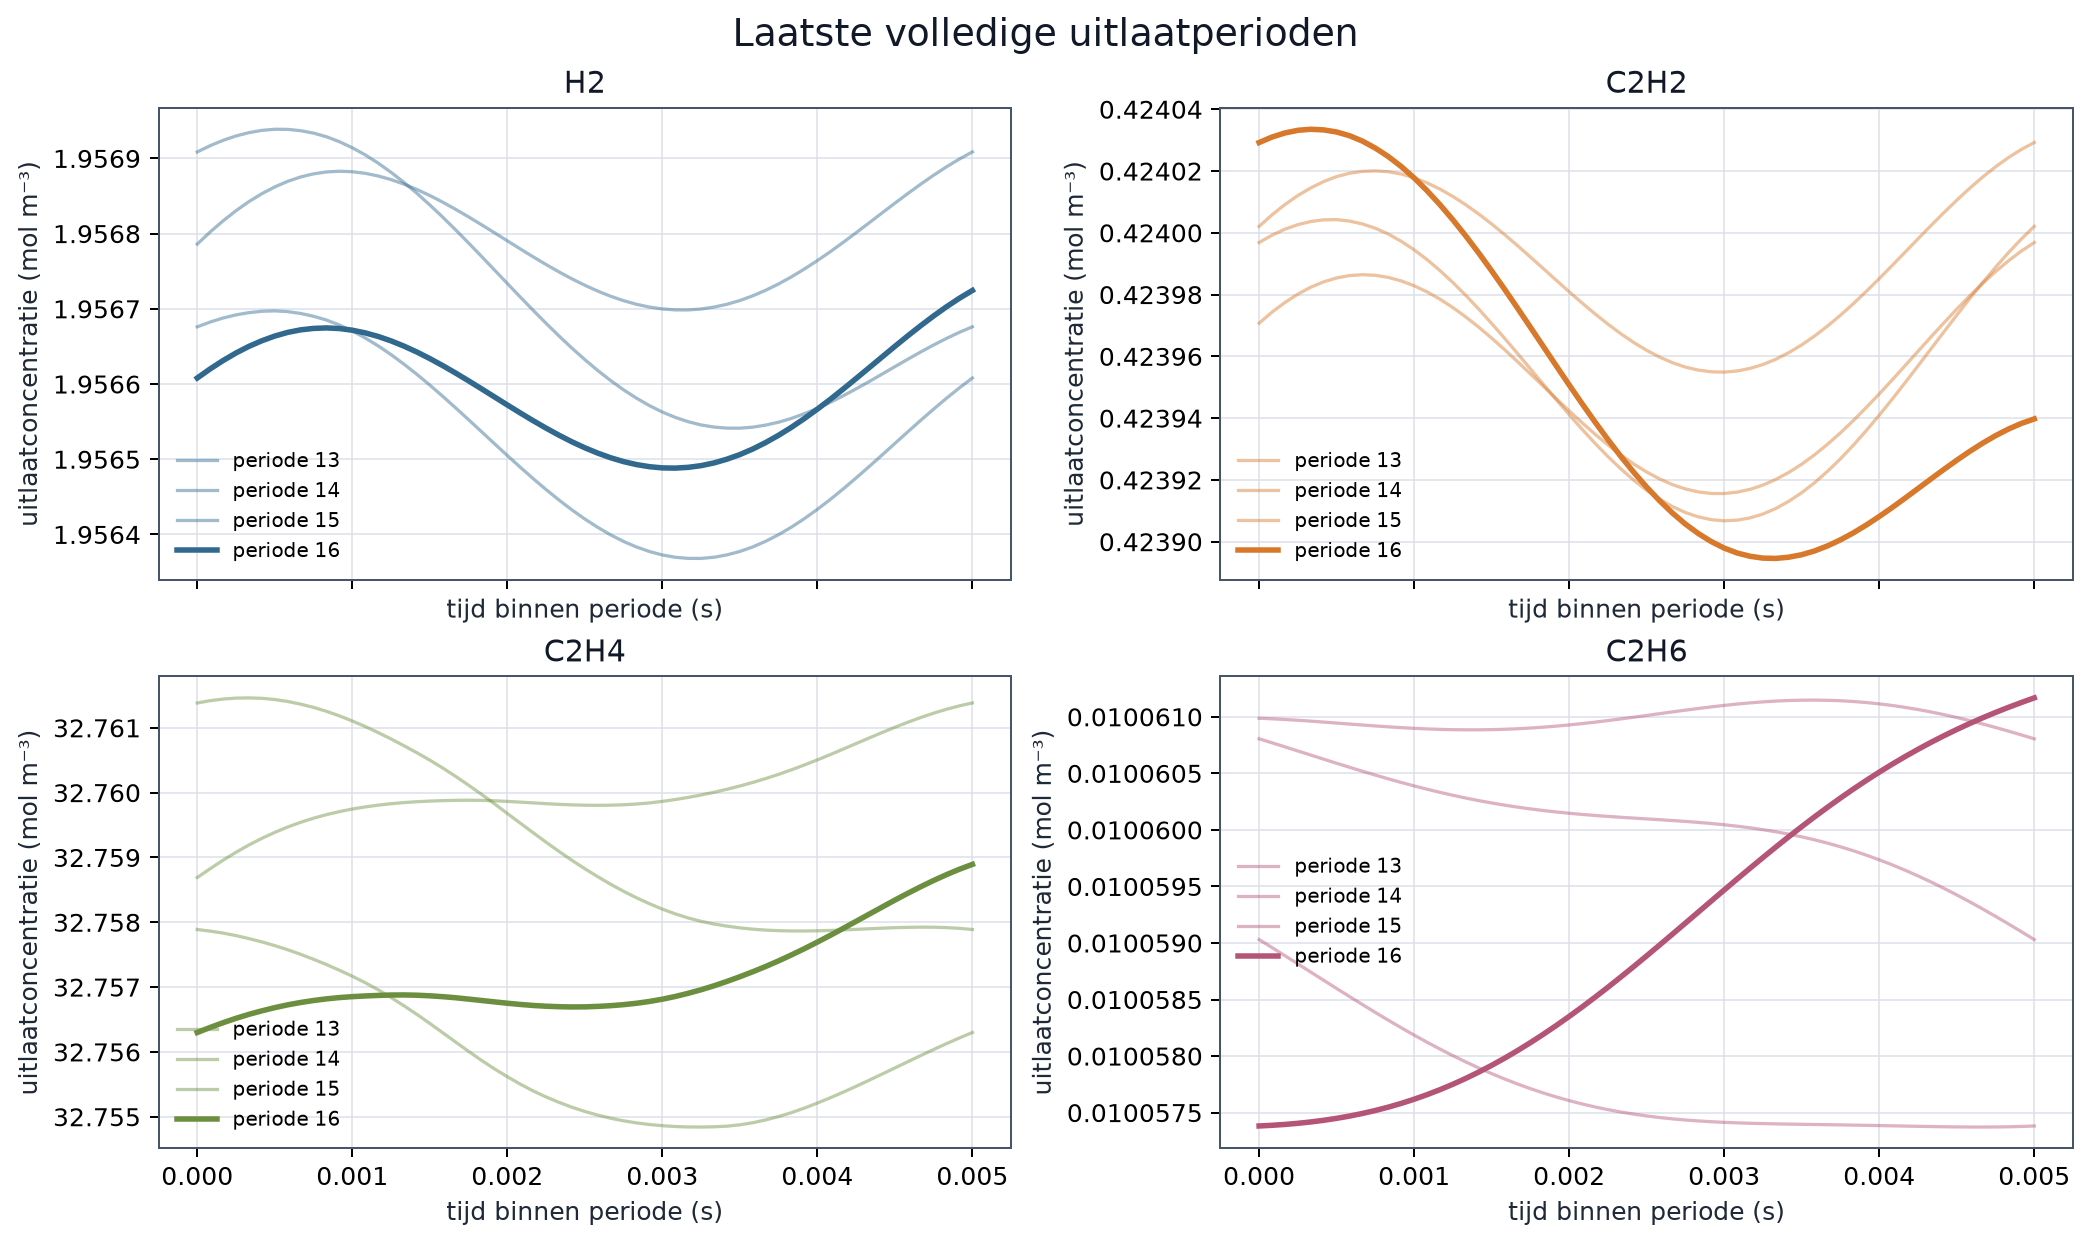

Figuur opgeslagen: notebooks/figures/last_cycles.png


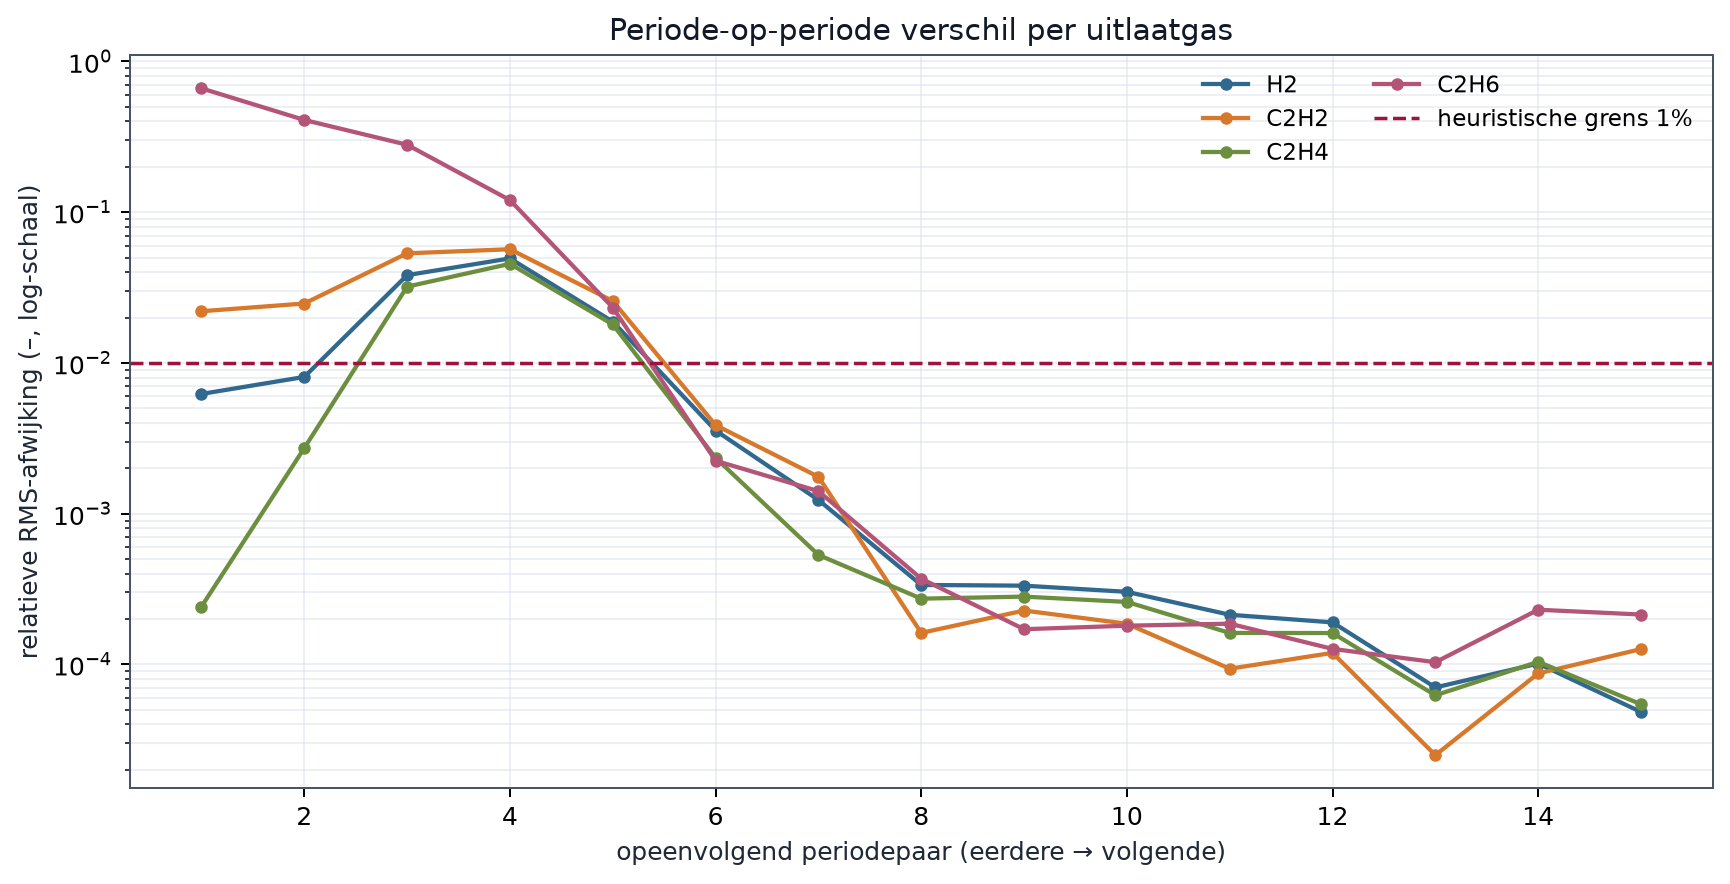

Figuur opgeslagen: notebooks/figures/settling_diagnostics.png


In [8]:
outlet_by_cycle = baseline["trajectory"].bulk[:, :, -1, :]
settling = analyse_settled_cycles(
    outlet_by_cycle,
    phase,
    SPECIES_NAMES,
    relative_tolerance=SETTLE_TOLERANCE,
    required_consecutive_pairs=SETTLE_REQUIRED_PAIRS,
    periods_to_summarise=3,
)

status = "ingeregeld volgens de ingestelde heuristiek" if settling.settled else "niet aangetoond"
print(f"Uitkomst: {status}")
print(f"Opeenvolgende slagende periodeparen aan het einde: {settling.converged_pairs_at_end}")
if settling.first_settled_cycle is not None:
    print(f"Start van de aaneengesloten ingeregelde suffix: periode {settling.first_settled_cycle + 1}")
print(f"Tolerantie per gas: {100 * SETTLE_TOLERANCE:.2f}% relatieve RMS")

last_pair_start = max(0, settling.relative_rms_error.shape[0] - 5)
pair_rows = []
for pair_index in range(last_pair_start, settling.relative_rms_error.shape[0]):
    errors = settling.relative_rms_error[pair_index]
    pair_passes = bool(np.all(errors <= SETTLE_TOLERANCE))
    values = " | ".join(f"{100 * value:.4g}%" for value in errors)
    pair_rows.append(
        f"| {pair_index + 1} → {pair_index + 2} | {values} | "
        f"{'ja' if pair_passes else 'nee'} |"
    )
pair_header = (
    "| Periodepaar | H₂ | C₂H₂ | C₂H₄ | C₂H₆ | Alle gassen binnen grens? |\n"
    "|---|---:|---:|---:|---:|---|"
)
display(
    Markdown(
        pair_header
        + "\n"
        + "\n".join(pair_rows)
        + "\n\nDe 1%-RMS-grens is een numerieke analyseheuristiek, geen bewijs van fysische of experimentele validiteit."
    )
)

if settling.settled:
    summary_rows = []
    for cycle in settling.summary_cycles:
        for species in SPECIES_NAMES:
            summary_rows.append(
                f"| {cycle['cycle']} | {species} | "
                f"{cycle['mean'][species]:.6g} | "
                f"{cycle['half_peak_to_peak'][species]:.6g} |"
            )
    summary_header = (
        "| Volledige periode | Gas | Gemiddelde C_uit (mol m⁻³) | "
        "Halve piek-piek C_uit (mol m⁻³) |\n|---:|---|---:|---:|"
    )
    display(
        Markdown(
            summary_header
            + "\n"
            + "\n".join(summary_rows)
            + "\n\nGemiddelden zijn trapeziumintegralen over iedere volledige periode."
        )
    )
else:
    display(
        Markdown(
            "Er is geen cyclusgemiddelde als ingeregeld gerapporteerd: "
            "de vereiste aaneengesloten suffix is niet aangetoond."
        )
    )

last_cycles = tuple(range(max(0, N_PERIODS - 4), N_PERIODS))
figure, _ = plot_cycle_overlay(phase, outlet_by_cycle, SPECIES_NAMES, last_cycles)
export_figure(figure, "last_cycles.png")

figure, _ = plot_settling_diagnostics(
    settling.relative_rms_error, SPECIES_NAMES, SETTLE_TOLERANCE
)
export_figure(figure, "settling_diagnostics.png")

## Gevoeligheid voor R, D_e en R²/D_e

De eerste drie gevallen gebruiken R = 37,5, 75 en 150 µm en schalen iedere soortspecifieke diffusiviteit als D_i × (R/R₀)². Zo blijven zowel R²/D_i als ε_pR²/D_i voor alle vier gassen gelijk. Het vierde geval houdt de diffusiviteitsfactor op 1 terwijl R verdubbelt; de verhoudingen worden dan viermaal groter.

De gelijke-verhoudingstrajecten zijn een implementatie-similariteitstest van de huidige PSSA-rechtskant. Overlappende curves zijn geen bronvalidatie en bewijzen niet dat een radiale toestand kan worden weggelaten. De vierde curve laat zien wat deze configuratie doet wanneer de verhouding verandert.

Basis · R×1, D×1: 0.46 s · nfev=890 · min C=0 mol m⁻³


R×0,5 · D×0,25 · zelfde R²/D: 0.43 s · nfev=890 · min C=0 mol m⁻³


R×2 · D×4 · zelfde R²/D: 0.41 s · nfev=890 · min C=0 mol m⁻³


R×2 · D×1 · R²/D ×4: 0.30 s · nfev=693 · min C=0 mol m⁻³


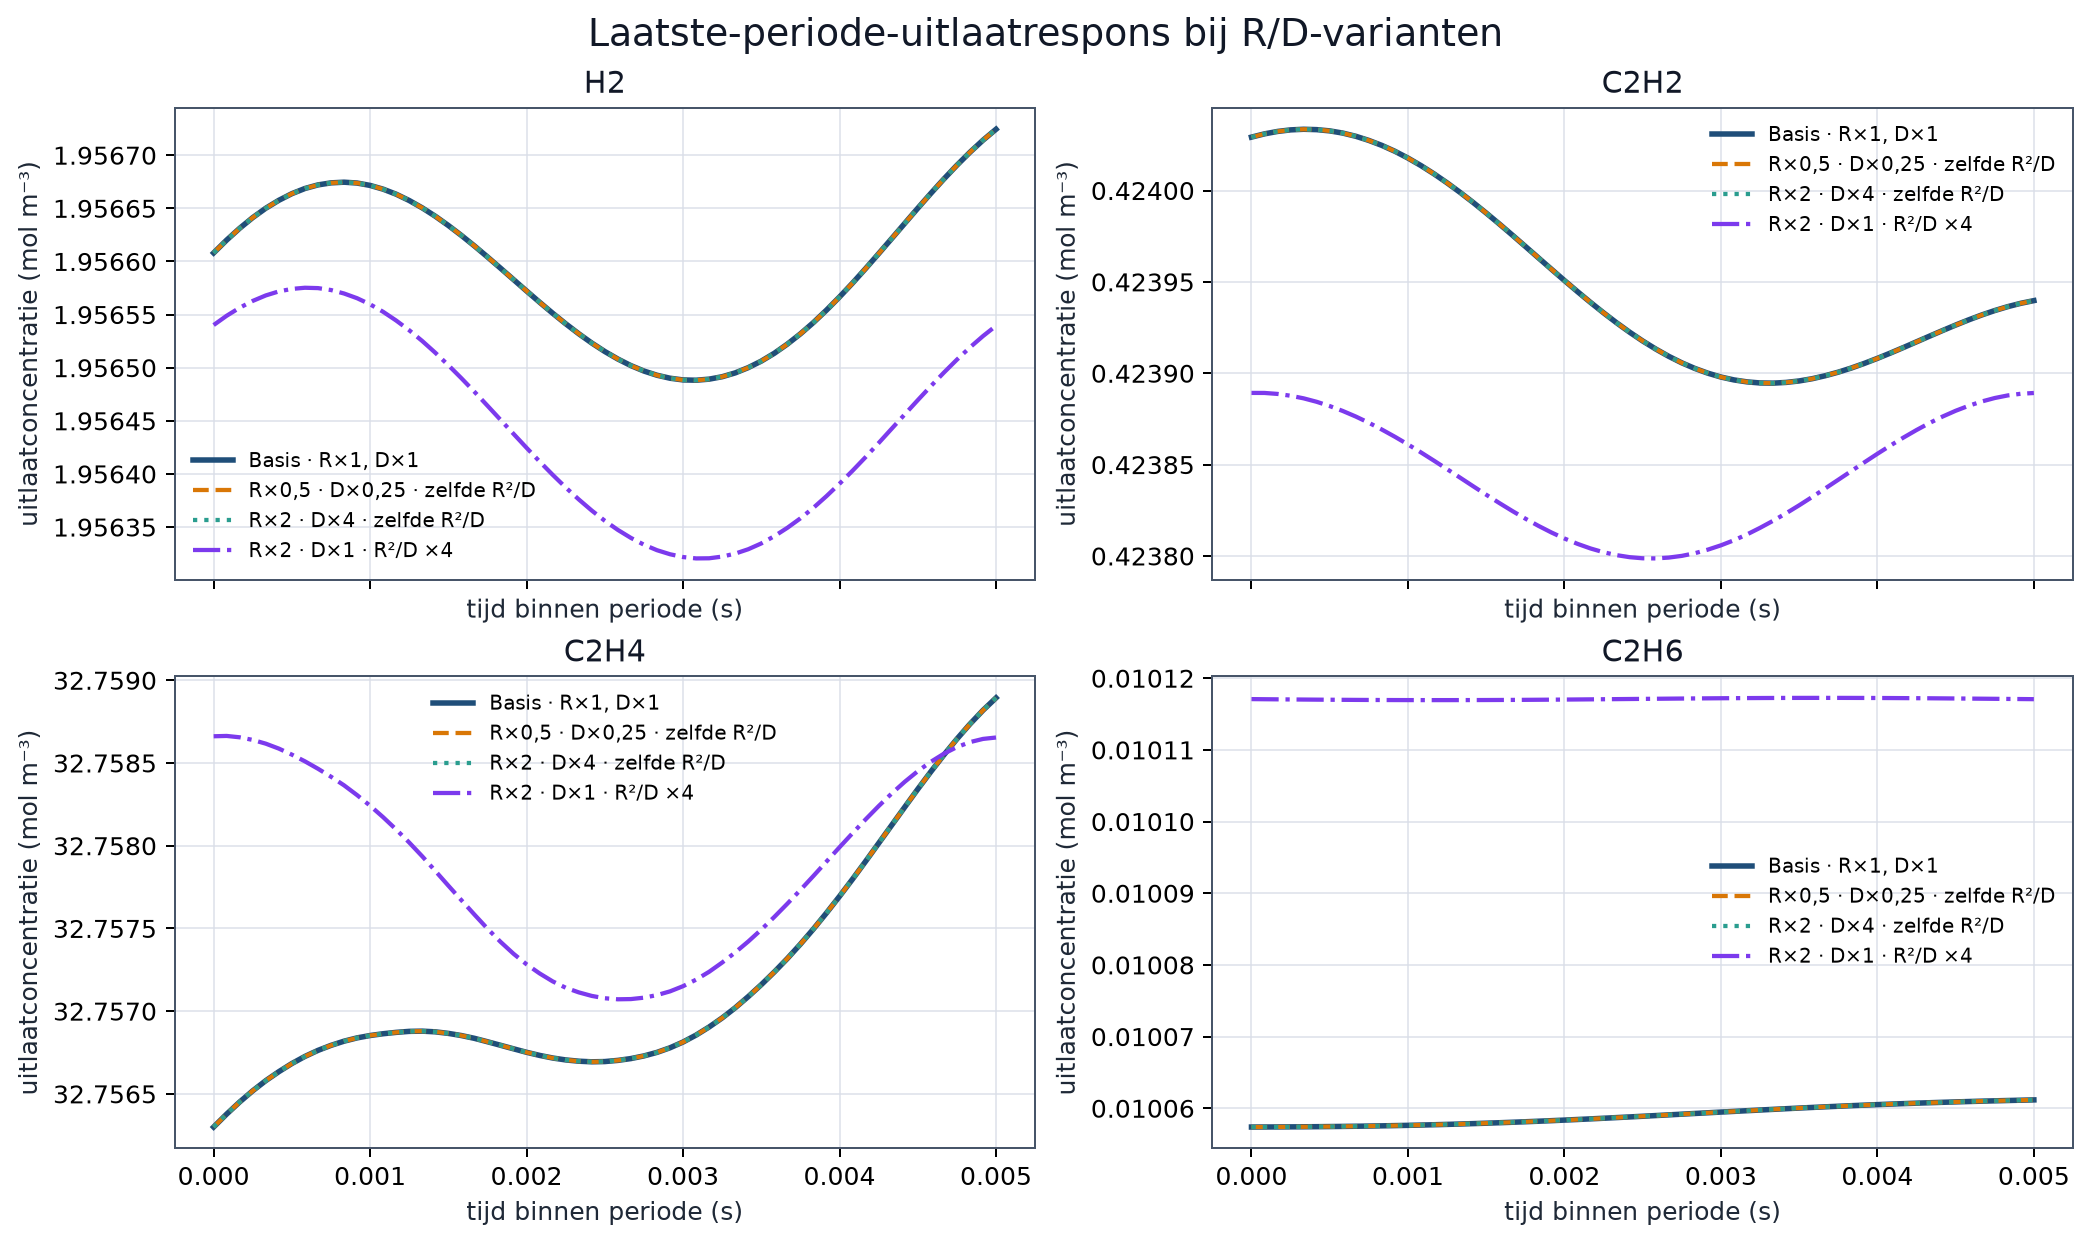

Figuur opgeslagen: notebooks/figures/radius_diffusivity_comparison.png


In [9]:
case_specs = (
    ("Basis · R×1, D×1", 1.0, 1.0),
    ("R×0,5 · D×0,25 · zelfde R²/D", 0.5, 0.25),
    ("R×2 · D×4 · zelfde R²/D", 2.0, 4.0),
    ("R×2 · D×1 · R²/D ×4", 2.0, 1.0),
)
case_results = []
for index, (label, radius_factor, diffusivity_factor) in enumerate(case_specs):
    result = baseline if index == 0 else run_case(radius_factor, diffusivity_factor)
    result["label"] = label
    result["outlet_last_cycle"] = result["trajectory"].bulk[-1, :, -1, :]
    case_results.append(result)
    print(
        f"{label}: {result['elapsed_s']:.2f} s · "
        f"nfev={result['solution'].nfev} · "
        f"min C={result['solution'].y.min():.4g} mol m⁻³"
    )

case_labels = tuple(result["label"] for result in case_results)
outlet_by_case = np.stack([result["outlet_last_cycle"] for result in case_results])
figure, _ = plot_parameter_comparison(
    phase, outlet_by_case, SPECIES_NAMES, case_labels
)
export_figure(figure, "radius_diffusivity_comparison.png")

In [10]:
comparison_rows = []
ratio_by_case = {}
for result in case_results:
    model = result["model"]
    radius = model.grid.r_p
    ratio_by_case[result["label"]] = {}
    for species in SPECIES_NAMES:
        diffusivity = float(model.diffusivities[species])
        bare_time = radius**2 / diffusivity
        pore_time = model.derived.particle_porosity * bare_time
        ratio_by_case[result["label"]][species] = bare_time
        comparison_rows.append(
            (
                result["label"],
                species,
                radius * 1e6,
                diffusivity,
                bare_time * 1e3,
                pore_time * 1e3,
            )
        )

header = (
    "| Geval | Gas | R (µm) | D_e (m²/s) | R²/D_e (ms) | ε_pR²/D_e (ms) |\n"
    "|---|---|---:|---:|---:|---:|"
)
body = "\n".join(
    f"| {label} | {species} | {radius:.1f} | {diffusivity:.3e} | "
    f"{bare:.4f} | {pore:.4f} |"
    for label, species, radius, diffusivity, bare, pore in comparison_rows
)
display(
    Markdown(
        header
        + "\n"
        + body
        + "\n\nD_e is porosity-inclusive. The last column is ε_pR²/D_e, the corresponding scale in the pore-gas balance."
    )
)

reference_outlet = case_results[0]["trajectory"].bulk[:, :, -1, :]
difference_rows = []
for case_index in range(1, len(case_results)):
    candidate = case_results[case_index]["trajectory"].bulk[:, :, -1, :]
    difference = np.abs(candidate - reference_outlet)
    max_absolute = np.max(difference, axis=(0, 1))
    scales = np.maximum(
        np.max(np.abs(reference_outlet), axis=(0, 1)),
        np.finfo(float).tiny,
    )
    max_relative = max_absolute / scales
    for species_index, species in enumerate(SPECIES_NAMES):
        difference_rows.append(
            f"| Basis ↔ {case_labels[case_index]} | {species} | "
            f"{max_absolute[species_index]:.3e} mol m⁻³ | "
            f"{max_relative[species_index]:.3e} |"
        )
difference_header = (
    "| Volledig gesimuleerd traject | Gas | Maximale absolute afwijking | "
    "Maximale relatieve afwijking |\n|---|---|---:|---:|"
)
display(
    Markdown(
        difference_header
        + "\n"
        + "\n".join(difference_rows)
        + "\n\nAfwijkingen vergelijken de volledige uitlaatgeschiedenis op gelijke tijdstippen, niet alleen de terminale snapshot."
    )
)

for matched_case in (1, 2):
    for species in SPECIES_NAMES:
        np.testing.assert_allclose(
            ratio_by_case[case_labels[matched_case]][species],
            ratio_by_case[case_labels[0]][species],
            rtol=2e-12,
            atol=0.0,
        )

| Geval | Gas | R (µm) | D_e (m²/s) | R²/D_e (ms) | ε_pR²/D_e (ms) |
|---|---|---:|---:|---:|---:|
| Basis · R×1, D×1 | H2 | 75.0 | 1.226e-05 | 0.4586 | 0.2293 |
| Basis · R×1, D×1 | C2H2 | 75.0 | 2.444e-06 | 2.3017 | 1.1509 |
| Basis · R×1, D×1 | C2H4 | 75.0 | 2.304e-06 | 2.4414 | 1.2207 |
| Basis · R×1, D×1 | C2H6 | 75.0 | 2.061e-06 | 2.7288 | 1.3644 |
| R×0,5 · D×0,25 · zelfde R²/D | H2 | 37.5 | 3.066e-06 | 0.4586 | 0.2293 |
| R×0,5 · D×0,25 · zelfde R²/D | C2H2 | 37.5 | 6.110e-07 | 2.3017 | 1.1509 |
| R×0,5 · D×0,25 · zelfde R²/D | C2H4 | 37.5 | 5.760e-07 | 2.4414 | 1.2207 |
| R×0,5 · D×0,25 · zelfde R²/D | C2H6 | 37.5 | 5.153e-07 | 2.7288 | 1.3644 |
| R×2 · D×4 · zelfde R²/D | H2 | 150.0 | 4.906e-05 | 0.4586 | 0.2293 |
| R×2 · D×4 · zelfde R²/D | C2H2 | 150.0 | 9.775e-06 | 2.3017 | 1.1509 |
| R×2 · D×4 · zelfde R²/D | C2H4 | 150.0 | 9.216e-06 | 2.4414 | 1.2207 |
| R×2 · D×4 · zelfde R²/D | C2H6 | 150.0 | 8.245e-06 | 2.7288 | 1.3644 |
| R×2 · D×1 · R²/D ×4 | H2 | 150.0 | 1.226e-05 | 1.8346 | 0.9173 |
| R×2 · D×1 · R²/D ×4 | C2H2 | 150.0 | 2.444e-06 | 9.2068 | 4.6034 |
| R×2 · D×1 · R²/D ×4 | C2H4 | 150.0 | 2.304e-06 | 9.7657 | 4.8829 |
| R×2 · D×1 · R²/D ×4 | C2H6 | 150.0 | 2.061e-06 | 10.9154 | 5.4577 |

D_e is porosity-inclusive. The last column is ε_pR²/D_e, the corresponding scale in the pore-gas balance.

| Volledig gesimuleerd traject | Gas | Maximale absolute afwijking | Maximale relatieve afwijking |
|---|---|---:|---:|
| Basis ↔ R×0,5 · D×0,25 · zelfde R²/D | H2 | 0.000e+00 mol m⁻³ | 0.000e+00 |
| Basis ↔ R×0,5 · D×0,25 · zelfde R²/D | C2H2 | 0.000e+00 mol m⁻³ | 0.000e+00 |
| Basis ↔ R×0,5 · D×0,25 · zelfde R²/D | C2H4 | 0.000e+00 mol m⁻³ | 0.000e+00 |
| Basis ↔ R×0,5 · D×0,25 · zelfde R²/D | C2H6 | 0.000e+00 mol m⁻³ | 0.000e+00 |
| Basis ↔ R×2 · D×4 · zelfde R²/D | H2 | 0.000e+00 mol m⁻³ | 0.000e+00 |
| Basis ↔ R×2 · D×4 · zelfde R²/D | C2H2 | 0.000e+00 mol m⁻³ | 0.000e+00 |
| Basis ↔ R×2 · D×4 · zelfde R²/D | C2H4 | 0.000e+00 mol m⁻³ | 0.000e+00 |
| Basis ↔ R×2 · D×4 · zelfde R²/D | C2H6 | 0.000e+00 mol m⁻³ | 0.000e+00 |
| Basis ↔ R×2 · D×1 · R²/D ×4 | H2 | 1.184e-03 mol m⁻³ | 5.352e-04 |
| Basis ↔ R×2 · D×1 · R²/D ×4 | C2H2 | 1.061e-03 mol m⁻³ | 2.062e-03 |
| Basis ↔ R×2 · D×1 · R²/D ×4 | C2H4 | 1.012e-01 mol m⁻³ | 2.810e-03 |
| Basis ↔ R×2 · D×1 · R²/D ×4 | C2H6 | 1.665e-04 mol m⁻³ | 1.650e-02 |

Afwijkingen vergelijken de volledige uitlaatgeschiedenis op gelijke tijdstippen, niet alleen de terminale snapshot.

## Wat is getest en wat blijft open?

Deze V2-branch voegt onafhankelijke, herhaalbare checks toe voor:

- nulreactie met een niet-uniform pelletprofiel: bulk- en porie-inventarisuitwisseling heft elkaar op;
- een reagerende bulk-plus-pellet-inventaris: de som is precies de volumegeïntegreerde pelletreactie één keer, en C/H-balans blijft nul;
- het algebraïsche oppervlak c_p(R)=C_b, de fysieke radiale eindige-volumeface en het symmetrievlak;
- Fuller-druk- en eenheidsconversies, effectieve diffusiviteiten op de catalogusconditie en partiaaldrukken met weggelaten inert;
- eindige-differentiedekking van de Jacobiaan-sparsitymasker en een stijve BDF-trajectvergelijking met sparse versus dense Jacobiaan;
- drie geïntegreerde, alle-gassen R²/D-paren en een vierde controle waarbij de verhouding verandert.

De settling-test vergelijkt vijf opeenvolgende eindperiodeparen met een 1%-relatieve-RMS-grens en blijft nadrukkelijk een heuristiek. Alleen bij een geslaagde suffix toont de notebook volledige periodegemiddelden voor alle gassen.

De uitgevoerde curves zijn code-diagnostiek met een Urmes 2019 PSSA-ratewet, niet bron-gematchte of experimenteel gevalideerde BEP-respons. De bestaande configuratie combineert aannames over reactorgeometrie, katalysatormassa en pelletporositeit/tortuositeit uit verschillende bronnen. Het is geen overeenkomst met het Urmès 2019-experiment; de dynamische θ-kinetiek, rooster-/tijdconvergentie, kalibratie en meetvergelijking blijven open.

## Uitvoerreceipt

Deze cel registreert de softwareversies en solverstatistieken van de gegenereerde figuren. De repositorytests staan los van de simulatie en zijn te draaien met de instructies in notebooks/README.md.

In [11]:
print(
    f"Python {platform.python_version()} · NumPy {np.__version__} · "
    f"SciPy {version('scipy')} · Pydantic {version('pydantic')}"
)
for result in case_results:
    solution = result["solution"]
    print(
        f"{result['label']}: success={solution.success}, "
        f"nfev={solution.nfev}, njev={solution.njev}, nlu={solution.nlu}, "
        f"wall={result['elapsed_s']:.3f} s"
    )

Python 3.12.14 · NumPy 2.5.3 · SciPy 1.18.0 · Pydantic 2.13.5
Basis · R×1, D×1: success=True, nfev=890, njev=4, nlu=80, wall=0.464 s
R×0,5 · D×0,25 · zelfde R²/D: success=True, nfev=890, njev=4, nlu=80, wall=0.434 s
R×2 · D×4 · zelfde R²/D: success=True, nfev=890, njev=4, nlu=80, wall=0.413 s
R×2 · D×1 · R²/D ×4: success=True, nfev=693, njev=1, nlu=75, wall=0.298 s
